# Fluid Mechanics — Computational Notebook
**Kee-Youn Yoo · PSE Lab · Seoul National University of Science and Technology**

This notebook provides interactive numerical computations and visualisations for all six chapters of the Fluid Mechanics course.  
Run each cell with **Shift+Enter**. No installation required — all packages are pre-installed in Colab.

| Chapter | Topic | Key computation |
|---------|-------|-----------------|
| Ch.1 | Kinematics | Pathlines vs streamlines |
| Ch.2 | Inviscid flows | Potential flow: cylinder with circulation |
| Ch.3 | Navier-Stokes | Poiseuille & Couette profiles; boundary-layer scaling |
| Ch.4 | Waves | Dispersion relations; phase vs group speed |
| Ch.5 | Instabilities | Kelvin-Helmholtz & Rayleigh-Bénard onset |
| Ch.6 | Turbulence | Kolmogorov scales; −5/3 energy spectrum |

In [1]:
# ── Common imports (run this cell first) ──────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec
from scipy.integrate import odeint, solve_ivp
from scipy.optimize import brentq

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'font.size': 11,
    'lines.linewidth': 2,
    'legend.fontsize': 10,
})
print('Setup complete.')

Setup complete.


---
## Chapter 1 — Kinematics: Pathlines vs Streamlines

**Velocity field:** $\mathbf{u} = (\alpha y t,\; \beta)$

- **Pathline:** integrate $d\mathbf{x}/dt = \mathbf{u}(\mathbf{x}(t), t)$ from $t=0$
- **Streamline:** at each fixed $t_0$, curves tangent to $\mathbf{u}(\mathbf{x}, t_0)$

For unsteady flow these differ — adjust $\alpha$ to see the effect.

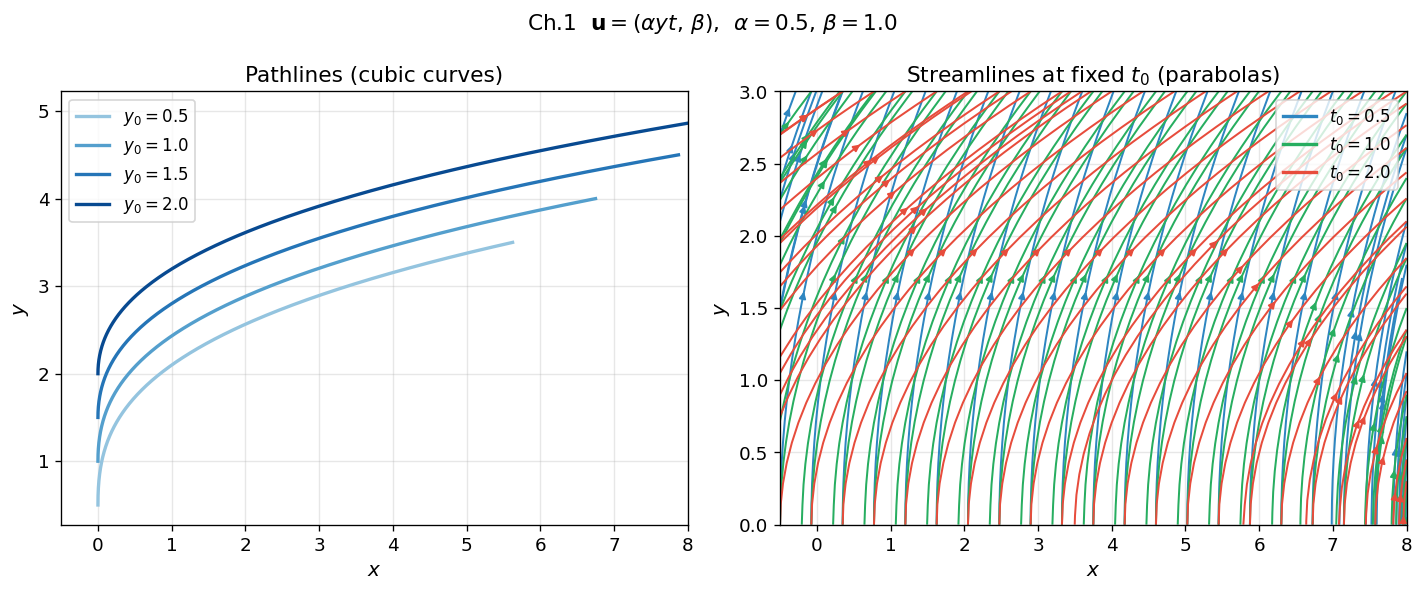

Observation: pathlines ≠ streamlines because ∂u/∂t ≠ 0 (unsteady flow).


In [2]:
# ── Ch.1  Pathlines vs Streamlines ───────────────────────────────────────────
alpha = 0.5   # ← try changing this (e.g. 0, 0.5, 1.0, 2.0)
beta  = 1.0

def velocity(t, state):
    x, y = state
    return [alpha * y * t, beta]

# --- Pathlines: integrate ODE for several starting points ---
t_span = (0, 3)
t_eval = np.linspace(0, 3, 400)
y0_list = [0.5, 1.0, 1.5, 2.0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(y0_list)))

ax = axes[0]
for y0, c in zip(y0_list, colors):
    sol = solve_ivp(velocity, t_span, [0, y0], t_eval=t_eval, method='RK45')
    ax.plot(sol.y[0], sol.y[1], color=c, label=f'$y_0={y0}$')
ax.set_xlabel('$x$'); ax.set_ylabel('$y$')
ax.set_title('Pathlines (cubic curves)')
ax.legend(); ax.set_xlim(-0.5, 8); ax.grid(True, alpha=0.3)

# --- Streamlines: at fixed t0 values ---
ax = axes[1]
x_grid = np.linspace(-0.5, 8, 30)
y_grid = np.linspace(0, 3, 20)
X, Y = np.meshgrid(x_grid, y_grid)

t0_values = [0.5, 1.0, 2.0]
sl_colors = ['#2E86C1', '#27AE60', '#E74C3C']
for t0, c in zip(t0_values, sl_colors):
    U = alpha * Y * t0
    V = np.ones_like(U) * beta
    ax.streamplot(x_grid, y_grid, U, V, color=c, density=0.7,
                  linewidth=1.2, arrowsize=0.8,
                  broken_streamlines=False)
    # dummy line for legend
    ax.plot([], [], color=c, label=f'$t_0={t0}$')

ax.set_xlabel('$x$'); ax.set_ylabel('$y$')
ax.set_title('Streamlines at fixed $t_0$ (parabolas)')
ax.legend(); ax.set_xlim(-0.5, 8); ax.grid(True, alpha=0.3)

fig.suptitle(r'Ch.1  $\mathbf{u}=(\alpha y t,\,\beta)$,  '
             f'$\\alpha={alpha}$, $\\beta={beta}$', fontsize=13)
plt.tight_layout(); plt.show()
print('Observation: pathlines ≠ streamlines because ∂u/∂t ≠ 0 (unsteady flow).')

---
## Chapter 2 — Potential Flow: Cylinder with Circulation

**Velocity potential:**
$$
\phi = U\!\left(r + \frac{R^2}{r}\right)\cos\theta + \frac{\Gamma}{2\pi}\theta
$$

**Lift (Magnus force):** $F_\perp = -\rho U \Gamma$

Adjust $\Gamma$ to see how circulation shifts stagnation points and creates lift.

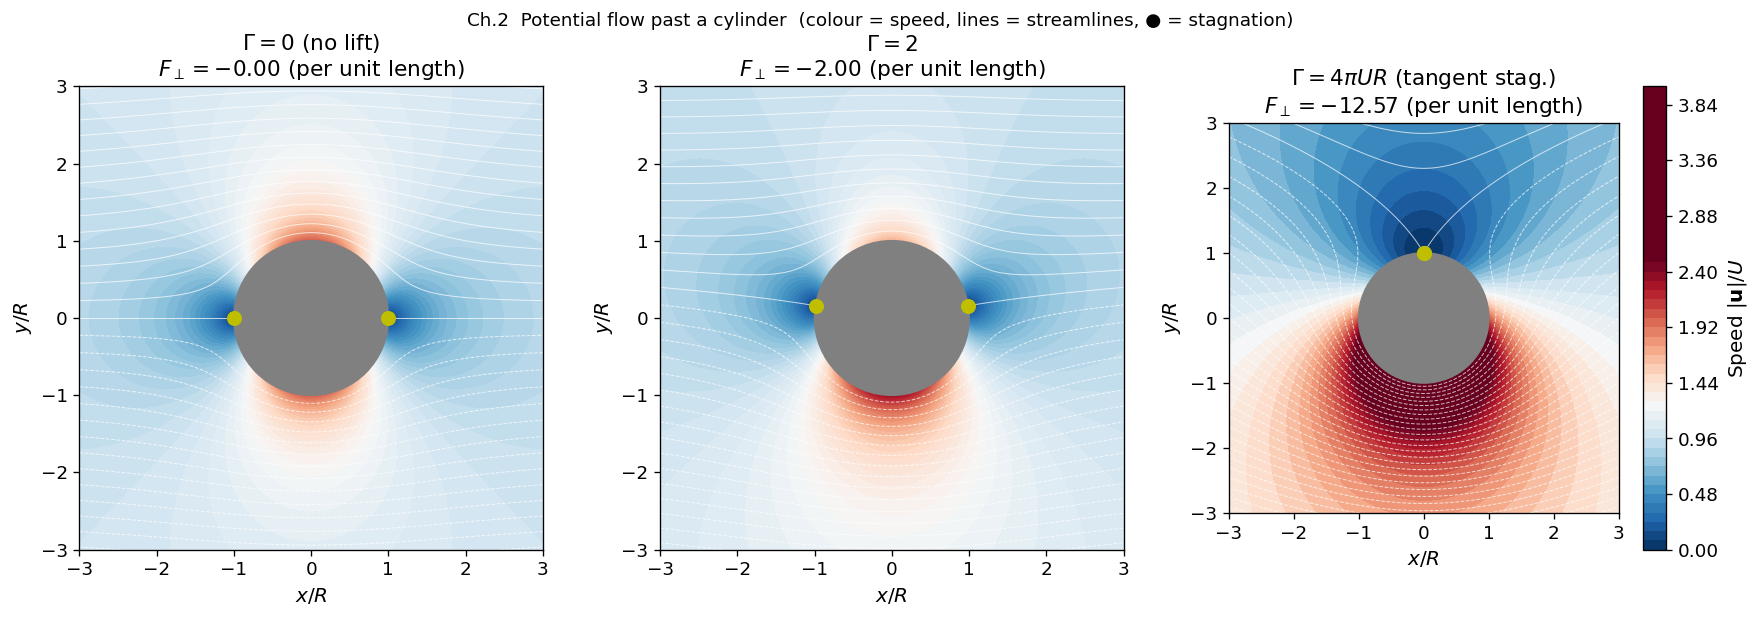

In [3]:
# ── Ch.2  Potential Flow around a Cylinder ───────────────────────────────────
U   = 1.0   # free-stream speed
R   = 1.0   # cylinder radius
rho = 1.0   # fluid density
Gamma_list = [0.0, 2.0, 4*np.pi*U*R]  # three circulation values
labels = ['$\\Gamma=0$ (no lift)', '$\\Gamma=2$', '$\\Gamma=4\\pi UR$ (tangent stag.)']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, Gamma, lbl in zip(axes, Gamma_list, labels):
    # Grid in Cartesian coordinates (exclude cylinder interior)
    x = np.linspace(-3, 3, 400)
    y = np.linspace(-3, 3, 400)
    X, Y = np.meshgrid(x, y)
    r     = np.sqrt(X**2 + Y**2)
    theta = np.arctan2(Y, X)
    mask  = r < R

    # Stream function  ψ = U(r - R²/r)sinθ - Γ/(2π) ln r
    psi = U * (r - R**2/r) * np.sin(theta) - Gamma/(2*np.pi) * np.log(np.where(mask, np.nan, r))
    psi[mask] = np.nan

    # Velocity components
    ur     = U * (1 - R**2/r**2) * np.cos(theta)
    utheta = -U * (1 + R**2/r**2) * np.sin(theta) + Gamma/(2*np.pi*np.where(r==0,1e-9,r))
    Vx = ur*np.cos(theta) - utheta*np.sin(theta)
    Vy = ur*np.sin(theta) + utheta*np.cos(theta)
    speed = np.sqrt(Vx**2 + Vy**2)
    speed[mask] = np.nan

    # Pressure from Bernoulli (on cylinder surface)
    theta_s = np.linspace(0, 2*np.pi, 500)
    u_surf   = -2*U*np.sin(theta_s) + Gamma/(2*np.pi*R)
    P_surf   = 0.5*rho*(U**2 - u_surf**2)   # ΔP relative to far field

    im = ax.contourf(X, Y, speed, levels=60, cmap='RdBu_r', vmin=0, vmax=2.5)
    ax.contour(X, Y, psi, levels=30, colors='white', linewidths=0.6, alpha=0.7)

    # Cylinder
    circle = plt.Circle((0,0), R, color='gray', zorder=5)
    ax.add_patch(circle)

    # Stagnation points on surface: u_θ(r=R)=0 => sin(θ) = Γ/(4πUR)
    sin_stag = Gamma/(4*np.pi*U*R)
    if abs(sin_stag) <= 1:
        t1 = np.arcsin(np.clip(sin_stag, -1, 1))   # first solution
        t2 = np.pi - t1                              # second solution
        for t_stag in [t1, t2]:
            ax.plot(R*np.cos(t_stag), R*np.sin(t_stag), 'yo', ms=8, zorder=6)

    F_lift = -rho * U * Gamma
    ax.set_title(f'{lbl}\n$F_\\perp = {F_lift:.2f}$ (per unit length)')
    ax.set_aspect('equal'); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
    ax.set_xlabel('$x/R$'); ax.set_ylabel('$y/R$')

plt.colorbar(im, ax=axes[-1], label='Speed $|\\mathbf{u}|/U$')
fig.suptitle('Ch.2  Potential flow past a cylinder  (colour = speed, lines = streamlines, ● = stagnation)',
             fontsize=11)
plt.tight_layout(); plt.show()

---
## Chapter 3 — Navier-Stokes: Exact Solutions & Boundary-Layer Scaling

### 3a. Poiseuille & Couette velocity profiles
### 3b. Boundary-layer thickness $\delta \sim Re^{-1/2}$

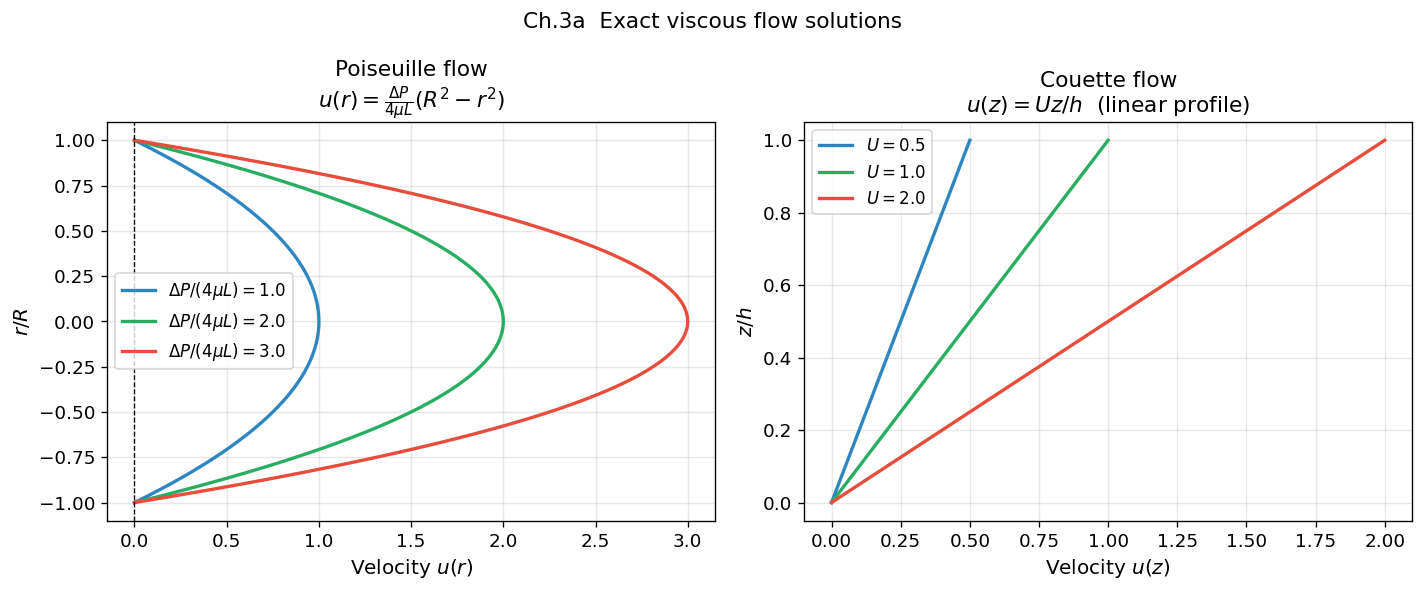

In [4]:
# ── Ch.3a  Poiseuille & Couette Profiles ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- Poiseuille (pipe, circular cross-section) ---
ax = axes[0]
R_pipe = 1.0
r = np.linspace(-R_pipe, R_pipe, 300)

dP_over_4muL_values = [1.0, 2.0, 3.0]   # = ΔP/(4μL)
colors_p = ['#2E86C1', '#27AE60', '#E74C3C']
for val, c in zip(dP_over_4muL_values, colors_p):
    u = val * (R_pipe**2 - r**2)
    ax.plot(u, r, color=c, label=f'$\\Delta P/(4\\mu L)={val}$')

ax.axvline(0, color='k', lw=0.8, ls='--')
ax.set_xlabel('Velocity $u(r)$'); ax.set_ylabel('$r / R$')
ax.set_title('Poiseuille flow\n$u(r) = \\frac{\\Delta P}{4\\mu L}(R^2-r^2)$')
ax.legend(); ax.grid(True, alpha=0.3)

# --- Couette flow ---
ax = axes[1]
h  = 1.0   # gap height
z  = np.linspace(0, h, 200)
U_plate_list = [0.5, 1.0, 2.0]
for U_plate, c in zip(U_plate_list, colors_p):
    u = U_plate * z / h
    ax.plot(u, z, color=c, label=f'$U={U_plate}$')

ax.set_xlabel('Velocity $u(z)$'); ax.set_ylabel('$z / h$')
ax.set_title('Couette flow\n$u(z) = U z/h$  (linear profile)')
ax.legend(); ax.grid(True, alpha=0.3)

fig.suptitle('Ch.3a  Exact viscous flow solutions', fontsize=13)
plt.tight_layout(); plt.show()

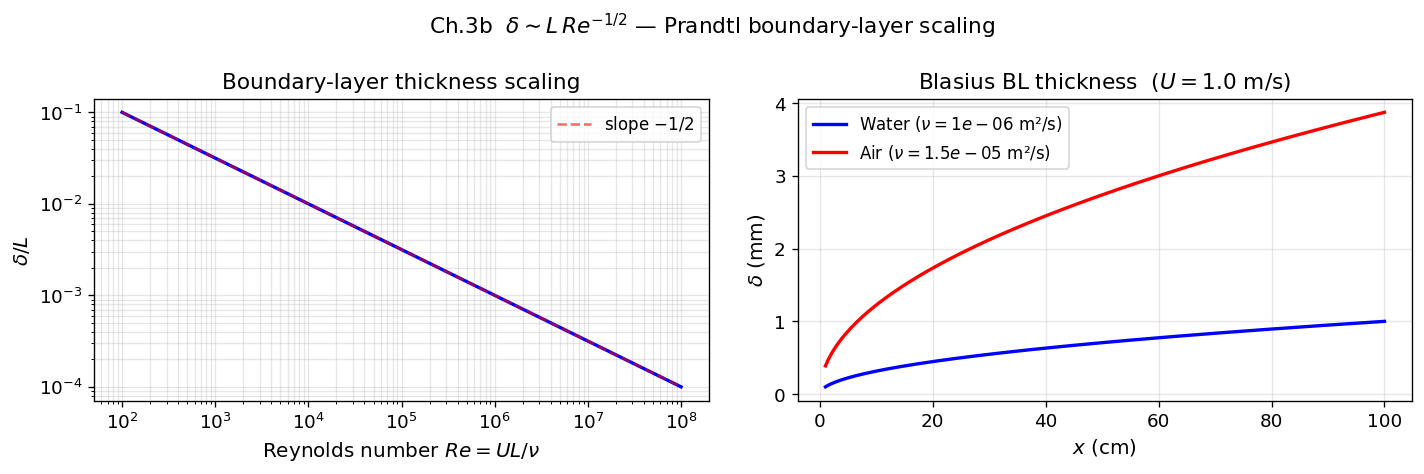

In [5]:
# ── Ch.3b  Boundary-Layer Thickness vs Reynolds Number ───────────────────────
Re_values = np.logspace(2, 8, 300)   # Re from 100 to 10^8
L = 1.0   # plate length

delta_over_L = L / np.sqrt(Re_values)   # δ/L ~ Re^{-1/2}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Log-log plot
ax = axes[0]
ax.loglog(Re_values, delta_over_L, 'b-', lw=2)
ax.loglog(Re_values, Re_values**(-0.5), 'r--', lw=1.5, alpha=0.6, label='slope $-1/2$')
ax.set_xlabel('Reynolds number $Re = UL/\\nu$')
ax.set_ylabel('$\\delta / L$')
ax.set_title('Boundary-layer thickness scaling')
ax.legend(); ax.grid(True, which='both', alpha=0.3)

# Physical thickness for water/air
ax = axes[1]
nu_water = 1e-6   # m²/s
nu_air   = 1.5e-5 # m²/s
U_flow   = 1.0    # m/s
x_vals   = np.linspace(0.01, 1.0, 200)  # distance along plate

Re_x_water = U_flow * x_vals / nu_water
Re_x_air   = U_flow * x_vals / nu_air
delta_water = x_vals / np.sqrt(Re_x_water)
delta_air   = x_vals / np.sqrt(Re_x_air)

ax.plot(x_vals * 100, delta_water * 1000, 'b-', label=f'Water ($\\nu={nu_water}$ m²/s)')
ax.plot(x_vals * 100, delta_air   * 1000, 'r-', label=f'Air ($\\nu={nu_air}$ m²/s)')
ax.set_xlabel('$x$ (cm)'); ax.set_ylabel('$\\delta$ (mm)')
ax.set_title(f'Blasius BL thickness  ($U={U_flow}$ m/s)')
ax.legend(); ax.grid(True, alpha=0.3)

fig.suptitle('Ch.3b  $\\delta \\sim L\\,Re^{-1/2}$ — Prandtl boundary-layer scaling', fontsize=13)
plt.tight_layout(); plt.show()

---
## Chapter 4 — Waves: Dispersion Relations

**General dispersion relation** (with gravity + surface tension):
$$
\omega^2 = \left(gk + \frac{\gamma k^3}{\rho}\right)\tanh(kH)
$$

Limits:
- Deep water, gravity only: $\omega^2 = gk$
- Shallow water: $\omega^2 = gHk^2$
- Capillary waves: $\omega^2 = \gamma k^3/\rho$

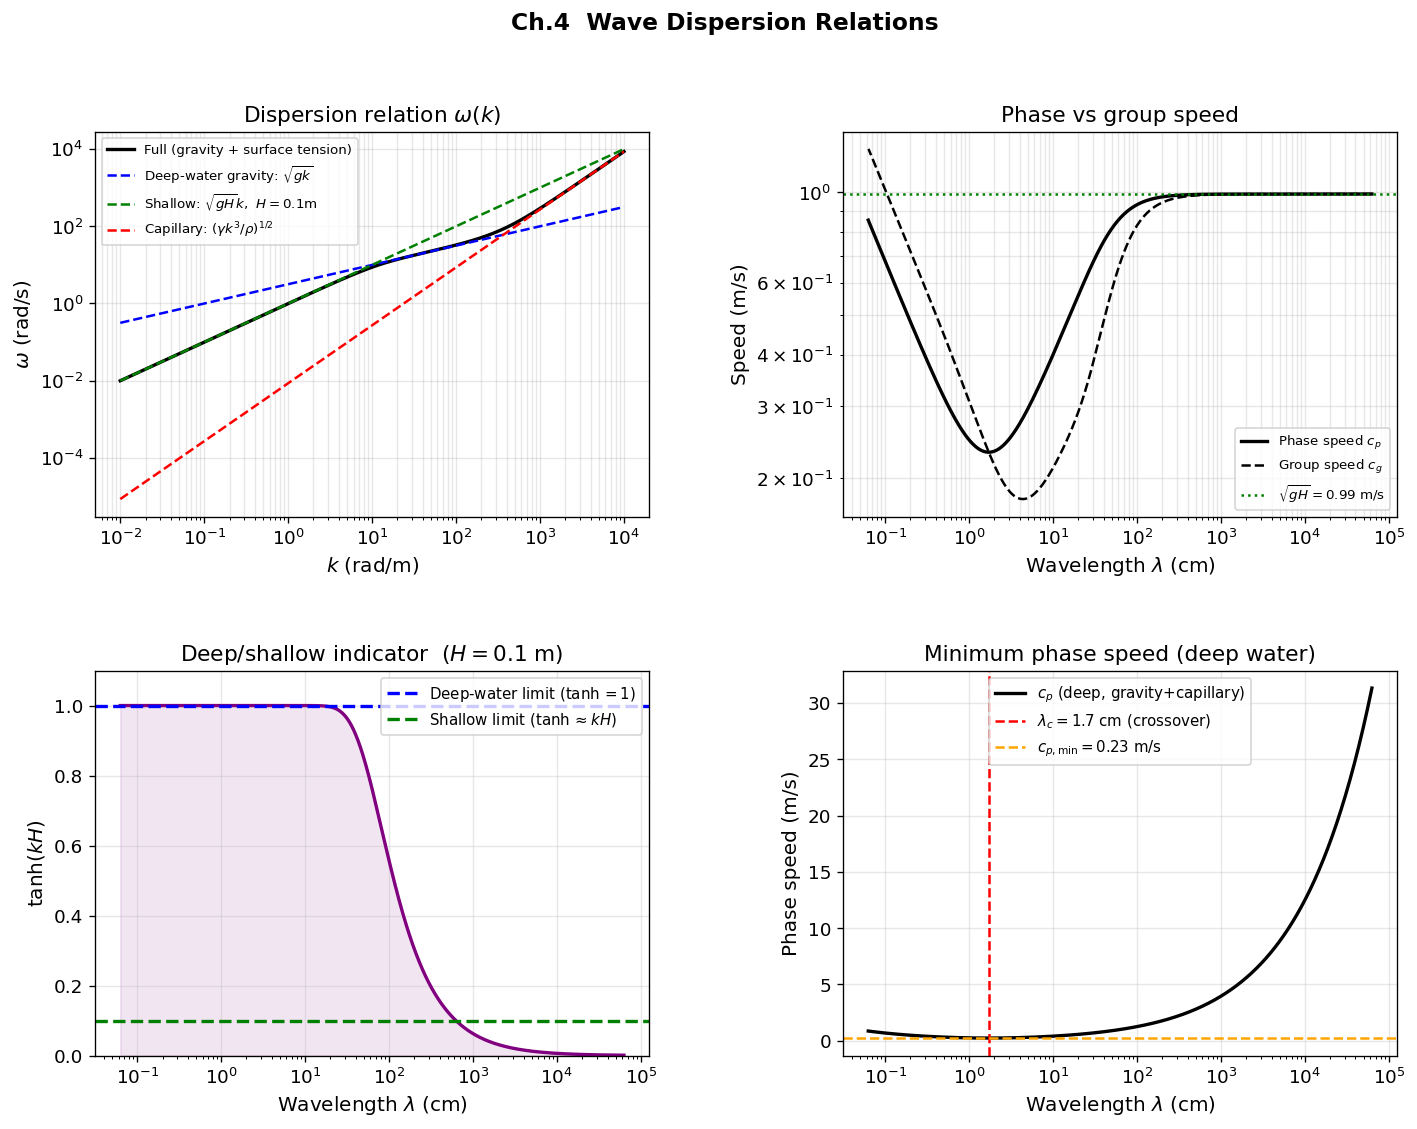

Capillary-gravity crossover wavelength: λ_c = 1.71 cm
Minimum phase speed (water): c_min = 0.231 m/s


In [6]:
# ── Ch.4  Dispersion Relations ────────────────────────────────────────────────
g     = 9.81       # m/s²
gamma = 0.073      # N/m  (water–air surface tension)
rho   = 1000.0     # kg/m³
H     = 0.1        # m  water depth  ← try 0.01 to 10.0

k  = np.logspace(-2, 4, 800)   # wavenumber (rad/m)
lam = 2*np.pi / k               # wavelength (m)

omega_full     = np.sqrt((g*k + gamma*k**3/rho) * np.tanh(k*H))
omega_deep_grav = np.sqrt(g * k)                         # deep, gravity only
omega_shallow  = np.sqrt(g * H) * k                      # shallow water
omega_capillary = np.sqrt(gamma * k**3 / rho)            # capillary limit

# Phase and group speeds
cp_full = omega_full / k
cg_full = np.gradient(omega_full, k)

fig = plt.figure(figsize=(14, 10))
gs  = GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.35)

# --- Panel 1: dispersion relation ω(k) ---
ax1 = fig.add_subplot(gs[0, 0])
ax1.loglog(k, omega_full,      'k-',  lw=2,   label='Full (gravity + surface tension)')
ax1.loglog(k, omega_deep_grav, 'b--', lw=1.5, label='Deep-water gravity: $\\sqrt{gk}$')
ax1.loglog(k, omega_shallow,   'g--', lw=1.5, label=f'Shallow: $\\sqrt{{gH}}k$,  $H={H}$m')
ax1.loglog(k, omega_capillary, 'r--', lw=1.5, label='Capillary: $(\\gamma k^3/\\rho)^{1/2}$')
ax1.set_xlabel('$k$ (rad/m)'); ax1.set_ylabel('$\\omega$ (rad/s)')
ax1.set_title('Dispersion relation $\\omega(k)$')
ax1.legend(fontsize=8); ax1.grid(True, which='both', alpha=0.3)

# --- Panel 2: phase speed ---
ax2 = fig.add_subplot(gs[0, 1])
ax2.loglog(lam*100, cp_full,            'k-',  lw=2,   label='Phase speed $c_p$')
ax2.loglog(lam*100, np.abs(cg_full),    'k--', lw=1.5, label='Group speed $c_g$')
ax2.axhline(np.sqrt(g*H), color='g', ls=':', lw=1.5, label=f'$\\sqrt{{gH}}={np.sqrt(g*H):.2f}$ m/s')
ax2.set_xlabel('Wavelength $\\lambda$ (cm)'); ax2.set_ylabel('Speed (m/s)')
ax2.set_title('Phase vs group speed')
ax2.legend(fontsize=8); ax2.grid(True, which='both', alpha=0.3)

# --- Panel 3: kH parameter (deep vs shallow indicator) ---
ax3 = fig.add_subplot(gs[1, 0])
kH = k * H
ax3.semilogx(lam*100, np.tanh(kH), 'purple', lw=2)
ax3.axhline(1.0, color='b', ls='--', label='Deep-water limit ($\\tanh=1$)')
ax3.axhline(0.1, color='g', ls='--', label='Shallow limit ($\\tanh\\approx kH$)')
ax3.fill_between(lam*100, 0, np.tanh(kH), alpha=0.1, color='purple')
ax3.set_xlabel('Wavelength $\\lambda$ (cm)'); ax3.set_ylabel('$\\tanh(kH)$')
ax3.set_title(f'Deep/shallow indicator  ($H={H}$ m)')
ax3.legend(fontsize=9); ax3.grid(True, alpha=0.3); ax3.set_ylim(0, 1.1)

# --- Panel 4: minimum phase speed (capillary-gravity crossover) ---
ax4 = fig.add_subplot(gs[1, 1])
# minimum cp in deep water
cp_deep = np.sqrt((g/k + gamma*k/rho))
k_min   = (g*rho/gamma)**0.5
cp_min  = (4*g*gamma/rho)**0.25
ax4.semilogx(lam*100, cp_deep, 'k-', lw=2, label='$c_p$ (deep, gravity+capillary)')
ax4.axvline(2*np.pi/k_min*100, color='r', ls='--', lw=1.5,
            label=f'$\\lambda_c={2*np.pi/k_min*100:.1f}$ cm (crossover)')
ax4.axhline(cp_min, color='orange', ls='--', lw=1.5,
            label=f'$c_{{p,\\min}}={cp_min:.2f}$ m/s')
ax4.set_xlabel('Wavelength $\\lambda$ (cm)'); ax4.set_ylabel('Phase speed (m/s)')
ax4.set_title('Minimum phase speed (deep water)')
ax4.legend(fontsize=9); ax4.grid(True, alpha=0.3)

fig.suptitle('Ch.4  Wave Dispersion Relations', fontsize=14, fontweight='bold')
plt.show()
print(f'Capillary-gravity crossover wavelength: λ_c = {2*np.pi/k_min*100:.2f} cm')
print(f'Minimum phase speed (water): c_min = {cp_min:.3f} m/s')

---
## Chapter 5 — Instabilities

### 5a. Kelvin-Helmholtz: growth rate vs wavenumber
### 5b. Rayleigh-Bénard: marginal stability curve & critical Ra

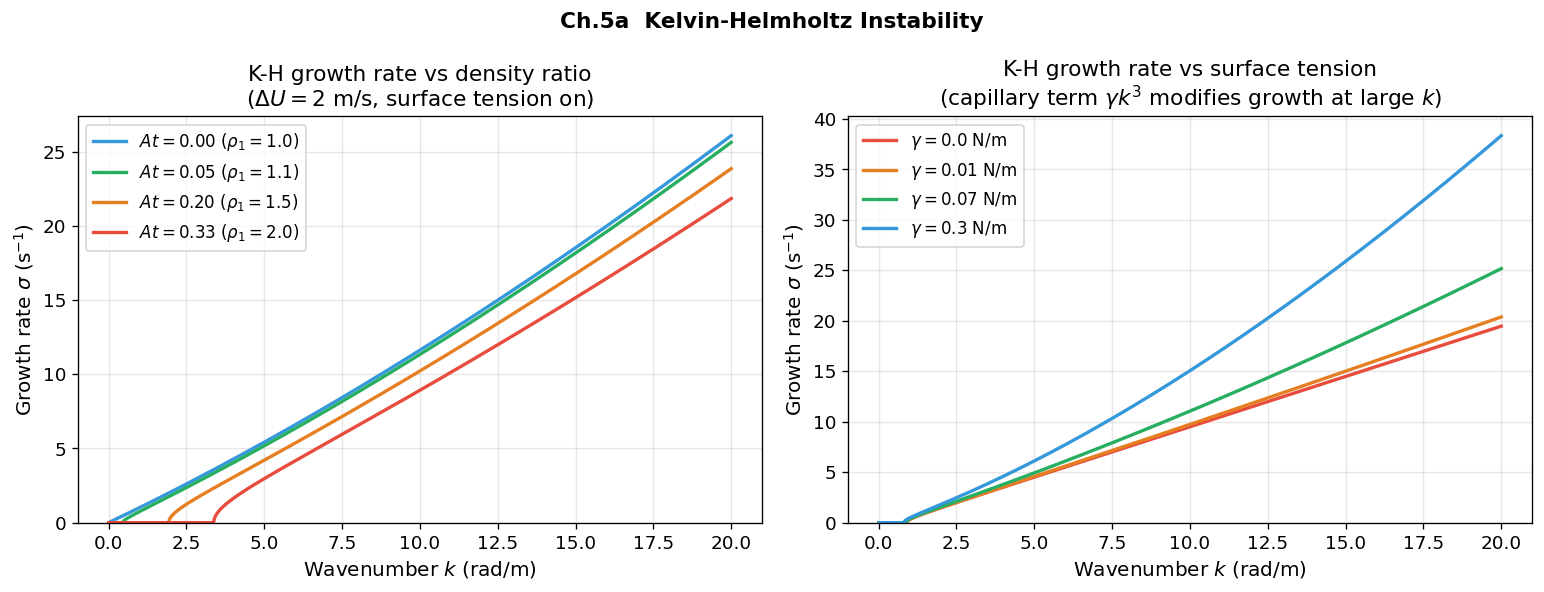

In [7]:
# ── Ch.5a  Kelvin-Helmholtz Growth Rate ──────────────────────────────────────
#
# Two layers: density ρ₁ (bottom), ρ₂ (top), velocities U₁, U₂
# Dispersion relation:
#   ω = k(ρ₁U₁+ρ₂U₂)/(ρ₁+ρ₂)  ±  i·σ
# where σ² = k²ρ₁ρ₂(U₁-U₂)²/(ρ₁+ρ₂)² - gk(ρ₁-ρ₂)/(ρ₁+ρ₂) + γk³/(ρ₁+ρ₂)

rho1  = 1.2    # heavy layer (rho1 > rho2; gravity stabilises long waves)
rho2  = 1.0    # light layer
U1    = 1.0    # heavy layer velocity
U2    = -1.0   # lower layer velocity (opposite direction)
g     = 9.81
gamma = 0.07   # N/m surface tension  ← set to 0 to remove capillary stabilisation

k = np.linspace(0.01, 20, 2000)

def KH_growth(k, rho1, rho2, U1, U2, g, gamma):
    """Return imaginary part of ω (growth rate σ). Positive = unstable."""
    r1r2  = rho1 * rho2
    r_sum = rho1 + rho2
    disc = (k**2 * r1r2 * (U1-U2)**2 / r_sum**2
            - g*k*(rho1-rho2)/r_sum
            + gamma*k**3/r_sum)
    sigma = np.sqrt(np.maximum(disc, 0.0))  # maximum avoids sqrt of negatives
    return sigma

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Panel 1: effect of density difference ---
ax = axes[0]
for rho1_val, c in zip([1.0, 1.1, 1.5, 2.0], ['#3498DB','#27AE60','#E67E22','#E74C3C']):
    sigma = KH_growth(k, rho1_val, rho2, U1, U2, g, gamma)
    At = (rho1_val - rho2)/(rho1_val + rho2)   # Atwood number
    ax.plot(k, sigma, color=c, label=f'$At={At:.2f}$ ($\\rho_1={rho1_val}$)')
ax.set_xlabel('Wavenumber $k$ (rad/m)'); ax.set_ylabel('Growth rate $\\sigma$ (s$^{-1}$)')
ax.set_title('K-H growth rate vs density ratio\n($\\Delta U=2$ m/s, surface tension on)')
ax.legend(); ax.grid(True, alpha=0.3); ax.set_ylim(bottom=0)

# --- Panel 2: effect of surface tension ---
ax = axes[1]
gamma_vals = [0.0, 0.01, 0.07, 0.3]
for gam, c in zip(gamma_vals, ['#E74C3C','#E67E22','#27AE60','#3498DB']):
    sigma = KH_growth(k, rho1, rho2, U1, U2, g, gam)
    ax.plot(k, sigma, color=c, label=f'$\\gamma={gam}$ N/m')
ax.set_xlabel('Wavenumber $k$ (rad/m)'); ax.set_ylabel('Growth rate $\\sigma$ (s$^{-1}$)')
ax.set_title('K-H growth rate vs surface tension\n(capillary term $\\gamma k^3$ modifies growth at large $k$)')
ax.legend(); ax.grid(True, alpha=0.3); ax.set_ylim(bottom=0)

fig.suptitle('Ch.5a  Kelvin-Helmholtz Instability', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

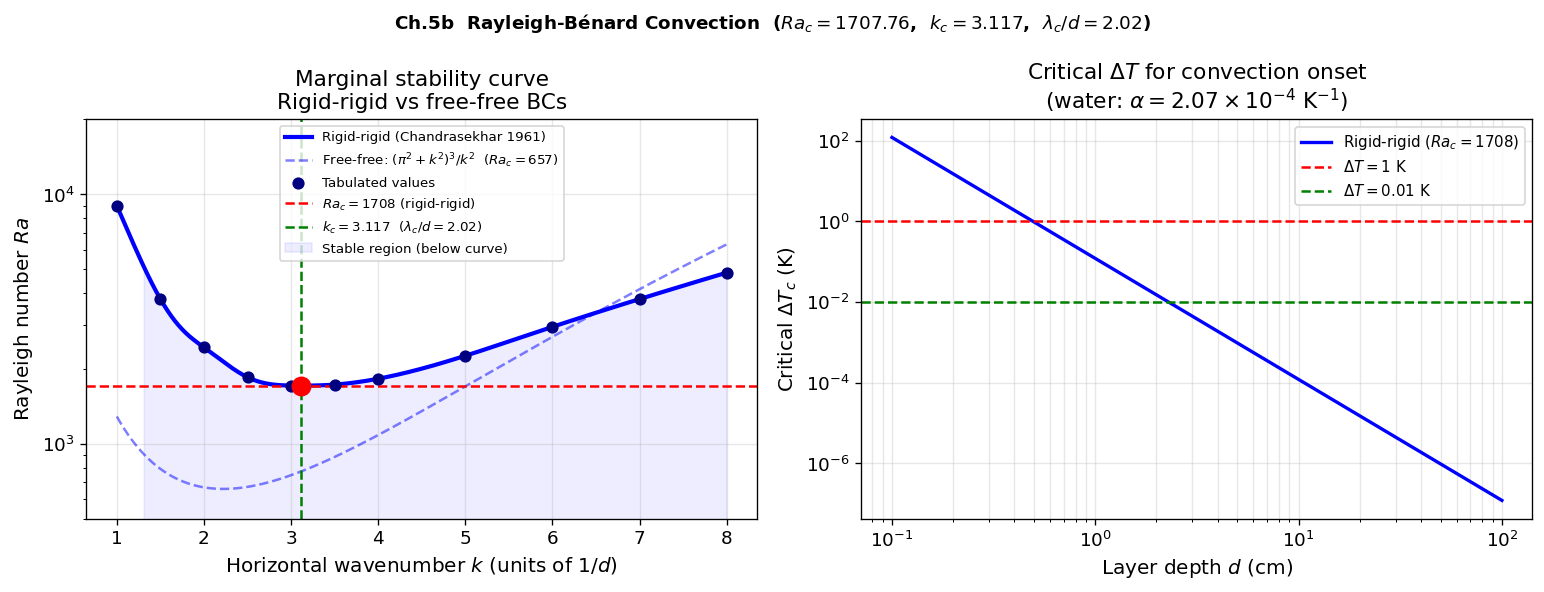

Rigid-rigid:  Ra_c = 1707.76,  k_c = 3.117,  λ_c/d = 2.016
Free-free:    Ra_c = 657.51,  k_c = 2.2214


In [8]:
# ── Ch.5b  Rayleigh-Bénard: Marginal Stability Curve ────────────────────────
#
# NOTE on boundary conditions:
#   FREE-FREE BCs (stress-free walls): Ra = (π² + k²)³ / k²  → Ra_c = 657.5
#   RIGID-RIGID BCs (no-slip walls):   requires solving a 6th-order ODE system
#                                       → Ra_c ≈ 1707.76  (Chandrasekhar 1961)
#
# Here we use tabulated values from Chandrasekhar (1961) Table II
# for RIGID-RIGID BCs (the physically relevant case for lab experiments).
from scipy.interpolate import CubicSpline

# Tabulated marginal stability curve: rigid-rigid BCs (Chandrasekhar 1961, Table II)
k_table  = np.array([1.0,  1.5,  2.0,   2.5,   3.0,   3.117, 3.5,   4.0,   5.0,   6.0,   7.0,   8.0])
Ra_table = np.array([9000, 3800, 2430.7,1845.3,1709.0,1707.76,1724.0,1820.0,2250.0,2940.0,3800.0,4850.0])

# Smooth spline through tabulated values
cs = CubicSpline(k_table, Ra_table)
k_RB  = np.linspace(1.0, 8.0, 1000)
Ra_curve = cs(k_RB)

# Critical values (analytical: k_c=3.117, Ra_c=1707.76)
k_c      = 3.117
Ra_c     = 1707.76
lambda_c = 2*np.pi / k_c   # critical wavelength in units of d

# FREE-FREE curve for comparison
Ra_ff = (np.pi**2 + k_RB**2)**3 / k_RB**2

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Panel 1: marginal stability curves ---
ax = axes[0]
ax.semilogy(k_RB, Ra_curve, 'b-',  lw=2.5, label='Rigid-rigid (Chandrasekhar 1961)')
ax.semilogy(k_RB, Ra_ff,    'b--', lw=1.5, alpha=0.5, label='Free-free: $(\\pi^2+k^2)^3/k^2$  ($Ra_c=657$)')
ax.scatter(k_table, Ra_table, color='navy', s=40, zorder=6, label='Tabulated values')
ax.axhline(Ra_c, color='r', ls='--', lw=1.5, label=f'$Ra_c = {Ra_c:.0f}$ (rigid-rigid)')
ax.axvline(k_c,  color='g', ls='--', lw=1.5, label=f'$k_c = {k_c}$  ($\\lambda_c/d = {lambda_c:.2f}$)')
ax.scatter([k_c], [Ra_c], color='red', s=120, zorder=7)
ax.fill_between(k_RB, 0, Ra_curve,
                where=Ra_curve < Ra_c * 3,
                alpha=0.07, color='blue', label='Stable region (below curve)')
ax.set_xlabel('Horizontal wavenumber $k$ (units of $1/d$)')
ax.set_ylabel('Rayleigh number $Ra$')
ax.set_title('Marginal stability curve\nRigid-rigid vs free-free BCs')
ax.set_ylim(500, 2e4); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# --- Panel 2: onset temperature difference vs layer depth ---
ax = axes[1]
g_val   = 9.81
alpha_T = 2.07e-4   # K⁻¹  thermal expansion (water at 20°C)
nu_val  = 1e-6      # m²/s kinematic viscosity (water)
kappa_v = 1.43e-7   # m²/s thermal diffusivity (water)

d_vals   = np.logspace(-3, 0, 300)   # layer depth 1 mm to 1 m
DeltaT_c = Ra_c * nu_val * kappa_v / (g_val * alpha_T * d_vals**3)

ax.loglog(d_vals * 100, DeltaT_c, 'b-', lw=2, label='Rigid-rigid ($Ra_c=1708$)')
ax.axhline(1.0,  color='r',  ls='--', lw=1.5, label='$\\Delta T = 1$ K')
ax.axhline(0.01, color='g',  ls='--', lw=1.5, label='$\\Delta T = 0.01$ K')
ax.set_xlabel('Layer depth $d$ (cm)')
ax.set_ylabel('Critical $\\Delta T_c$ (K)')
ax.set_title('Critical $\\Delta T$ for convection onset\n(water: $\\alpha=2.07\\times10^{-4}$ K$^{-1}$)')
ax.legend(fontsize=9); ax.grid(True, which='both', alpha=0.3)

fig.suptitle(f'Ch.5b  Rayleigh-Bénard Convection  ($Ra_c = {Ra_c}$,  $k_c = {k_c}$,  $\\lambda_c/d = {lambda_c:.2f}$)',
             fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()
print(f'Rigid-rigid:  Ra_c = {Ra_c},  k_c = {k_c},  λ_c/d = {lambda_c:.3f}')
print(f'Free-free:    Ra_c = {27*np.pi**4/4:.2f},  k_c = {np.pi/np.sqrt(2):.4f}')

---
## Chapter 6 — Turbulence: Kolmogorov Scales & Energy Spectrum

### 6a. Kolmogorov microscales vs Reynolds number
### 6b. Model energy spectrum $E(k)$ with −5/3 inertial range

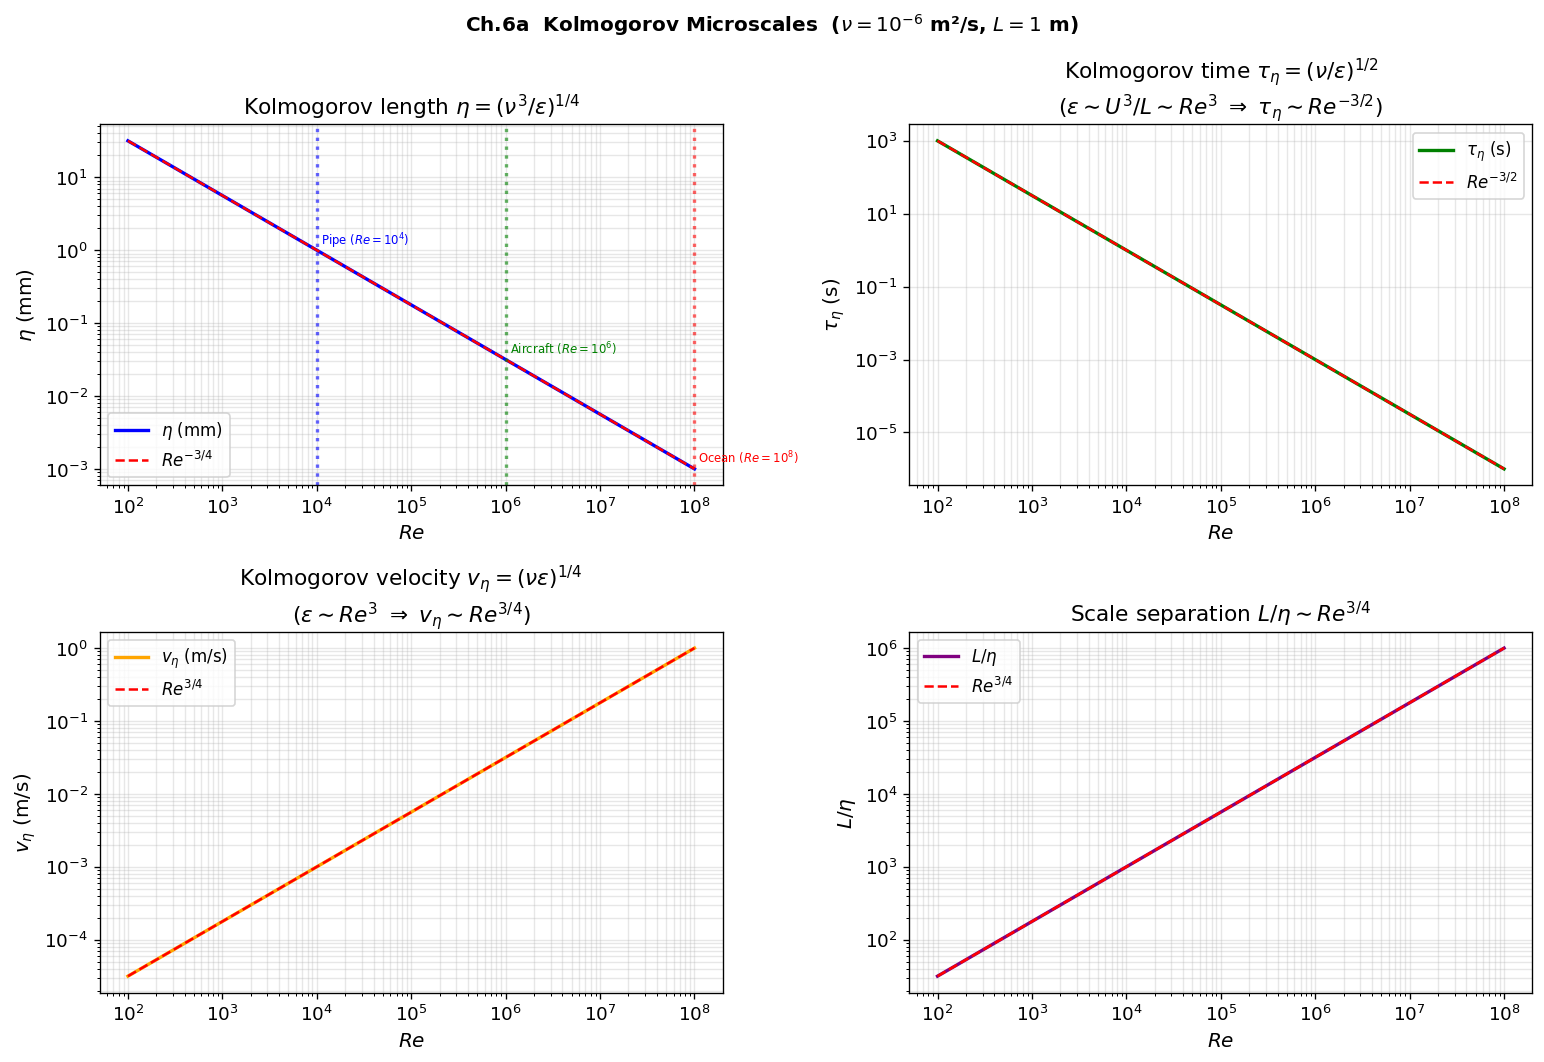

In [9]:
# ── Ch.6a  Kolmogorov Scales vs Reynolds Number ───────────────────────────────
#
# Given: integral scale L, large-scale velocity U, kinematic viscosity ν
# Dissipation rate: ε ~ U³/L
# Kolmogorov:  η = (ν³/ε)^{1/4},  τ_η = (ν/ε)^{1/2},  v_η = (νε)^{1/4}

nu  = 1e-6   # m²/s  (water)
L   = 1.0    # m  integral scale

Re_vals = np.logspace(2, 8, 500)     # Re = UL/ν
U_vals  = Re_vals * nu / L
eps     = U_vals**3 / L              # ε ~ U³/L

eta_vals   = (nu**3 / eps)**0.25     # Kolmogorov length
tau_vals   = (nu / eps)**0.5         # Kolmogorov time
v_eta_vals = (nu * eps)**0.25        # Kolmogorov velocity
L_over_eta = L / eta_vals            # scale separation

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

ax = axes[0, 0]
ax.loglog(Re_vals, eta_vals * 1000, 'b-', lw=2, label='$\\eta$ (mm)')
ax.set_xlabel('$Re$'); ax.set_ylabel('$\\eta$ (mm)')
ax.set_title('Kolmogorov length $\\eta = (\\nu^3/\\varepsilon)^{1/4}$')
ax.grid(True, which='both', alpha=0.3)
# Slope reference
ax.loglog(Re_vals, 1e3 * Re_vals**(-0.75), 'r--', lw=1.5, label='$Re^{-3/4}$')
ax.legend()

ax = axes[0, 1]
ax.loglog(Re_vals, tau_vals, 'g-', lw=2, label='$\\tau_\\eta$ (s)')
ax.loglog(Re_vals, 1e6 * Re_vals**(-1.5), 'r--', lw=1.5, label='$Re^{-3/2}$')
ax.set_xlabel('$Re$'); ax.set_ylabel('$\\tau_\\eta$ (s)')
ax.set_title('Kolmogorov time $\\tau_\\eta = (\\nu/\\varepsilon)^{1/2}$\n($\\varepsilon\\sim U^3/L\\sim Re^3$ $\\Rightarrow$ $\\tau_\\eta\\sim Re^{-3/2}$)')
ax.legend(); ax.grid(True, which='both', alpha=0.3)

ax = axes[1, 0]
ax.loglog(Re_vals, v_eta_vals, 'orange', lw=2, label='$v_\\eta$ (m/s)')
ax.loglog(Re_vals, 1e-6 * Re_vals**0.75, 'r--', lw=1.5, label='$Re^{3/4}$')
ax.set_xlabel('$Re$'); ax.set_ylabel('$v_\\eta$ (m/s)')
ax.set_title('Kolmogorov velocity $v_\\eta = (\\nu\\varepsilon)^{1/4}$\n($\\varepsilon\\sim Re^3$ $\\Rightarrow$ $v_\\eta\\sim Re^{3/4}$)')
ax.legend(); ax.grid(True, which='both', alpha=0.3)

ax = axes[1, 1]
ax.loglog(Re_vals, L_over_eta, 'purple', lw=2, label='$L/\\eta$')
ax.loglog(Re_vals, Re_vals**0.75, 'r--', lw=1.5, label='$Re^{3/4}$')
ax.set_xlabel('$Re$'); ax.set_ylabel('$L/\\eta$')
ax.set_title('Scale separation $L/\\eta \\sim Re^{3/4}$')
ax.legend(); ax.grid(True, which='both', alpha=0.3)

# Annotate practical examples
examples = [
    ('Pipe ($Re=10^4$)', 1e4, 'b'),
    ('Aircraft ($Re=10^6$)', 1e6, 'g'),
    ('Ocean ($Re=10^8$)', 1e8, 'r'),
]
for name, Re_ex, c in examples:
    U_ex   = Re_ex * nu / L
    eps_ex = U_ex**3 / L
    eta_ex = (nu**3/eps_ex)**0.25 * 1000
    axes[0,0].axvline(Re_ex, color=c, ls=':', alpha=0.6)
    axes[0,0].text(Re_ex*1.1, eta_ex*1.2, name, fontsize=7, color=c)

fig.suptitle('Ch.6a  Kolmogorov Microscales  ($\\nu=10^{-6}$ m²/s, $L=1$ m)', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

Re = 1e+08,  L = 1.0 m,  η = 1.000 μm
L/η = 1000000  (scale separation,  ~ Re^(3/4) = 1000000)
Inertial range slope = -1.6935  (exact -5/3 = -1.6667 at Re→∞)


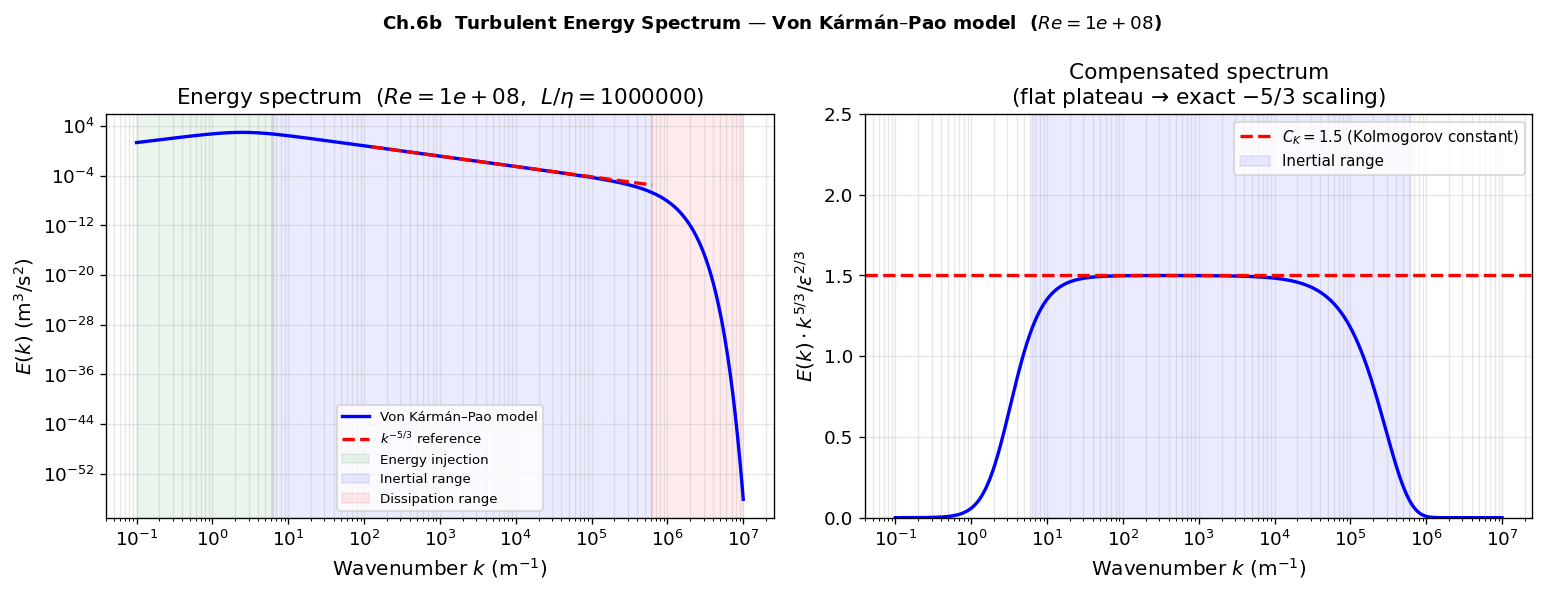

In [10]:
# ── Ch.6b  Model Energy Spectrum with −5/3 Inertial Range ────────────────────
#
# Von Kármán–Pao model spectrum (Pope 2000, eq. 6.246):
#   E(k) = C_K ε^{2/3} k^{-5/3} f_L(kL) f_η(kη)
#
# f_L: suppresses energy-containing range (large scales)
# f_η: suppresses dissipation range (small scales)
# NOTE: exact -5/3 is only achieved in the limit Re → ∞.
#       At finite Re the inertial range is finite and the slope is slightly steeper.

C_K = 1.5        # Kolmogorov constant
Re_turb = 1e8    # turbulent Reynolds number  ← try 1e4, 1e6, 1e8
nu_turb = 1e-6   # kinematic viscosity (m²/s)
L_turb  = 1.0    # integral length scale (m)

U_turb  = Re_turb * nu_turb / L_turb
eps_turb= U_turb**3 / L_turb
eta_turb= (nu_turb**3 / eps_turb)**0.25

print(f'Re = {Re_turb:.0e},  L = {L_turb} m,  η = {eta_turb*1e6:.3f} μm')
print(f'L/η = {L_turb/eta_turb:.0f}  (scale separation,  ~ Re^(3/4) = {Re_turb**0.75:.0f})')

# Wavenumber range
k1 = 0.1 / L_turb
k2 = 10  / eta_turb
k_spec = np.logspace(np.log10(k1), np.log10(k2), 3000)

def energy_spectrum(k, eps, L, eta, CK):
    """Von Kármán–Pao model spectrum (Pope 2000)."""
    # Energy-containing range suppression
    f_L = (k*L / np.sqrt((k*L)**2 + 6.78))**(5/3 + 3/2)
    # Dissipation range suppression (corrected: no constant offset)
    f_eta = np.exp(-5.2 * (k*eta)**(4/3))
    return CK * eps**(2/3) * k**(-5/3) * f_L * f_eta

E_spec = energy_spectrum(k_spec, eps_turb, L_turb, eta_turb, C_K)

# Reference −5/3 line through mid-inertial range
k_L   = 2*np.pi / L_turb
k_eta = 2*np.pi / eta_turb
k_ref = np.array([20*k_L, 0.1*k_eta])
E_ref = C_K * eps_turb**(2/3) * k_ref**(-5/3)

# Measure inertial range slope
mask_ir = (k_spec > 30*k_L) & (k_spec < k_eta/50)
if mask_ir.sum() > 10:
    slope_ir = np.polyfit(np.log10(k_spec[mask_ir]), np.log10(E_spec[mask_ir]), 1)[0]
    print(f'Inertial range slope = {slope_ir:.4f}  (exact -5/3 = {-5/3:.4f} at Re→∞)')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Panel 1: energy spectrum ---
ax = axes[0]
ax.loglog(k_spec, E_spec, 'b-',  lw=2,   label='Von Kármán–Pao model')
ax.loglog(k_ref,  E_ref,  'r--', lw=2,   label='$k^{-5/3}$ reference')
ax.axvspan(k1,        k_L,      alpha=0.08, color='green', label='Energy injection')
ax.axvspan(k_L,       k_eta/10, alpha=0.08, color='blue',  label='Inertial range')
ax.axvspan(k_eta/10,  k2,       alpha=0.08, color='red',   label='Dissipation range')
ax.set_xlabel('Wavenumber $k$ (m$^{-1}$)')
ax.set_ylabel('$E(k)$ (m$^3$/s$^2$)')
ax.set_title(f'Energy spectrum  ($Re={Re_turb:.0e}$,  $L/\\eta={L_turb/eta_turb:.0f}$)')
ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)

# --- Panel 2: compensated spectrum ---
ax = axes[1]
comp = E_spec * k_spec**(5/3) / eps_turb**(2/3)
ax.semilogx(k_spec, comp, 'b-', lw=2)
ax.axhline(C_K, color='r', ls='--', lw=2, label=f'$C_K = {C_K}$ (Kolmogorov constant)')
ax.axvspan(k_L, k_eta/10, alpha=0.08, color='blue', label='Inertial range')
ax.set_xlabel('Wavenumber $k$ (m$^{-1}$)')
ax.set_ylabel('$E(k)\\cdot k^{5/3} / \\varepsilon^{2/3}$')
ax.set_title('Compensated spectrum\n(flat plateau → exact $-5/3$ scaling)')
ax.legend(fontsize=9); ax.grid(True, which='both', alpha=0.3)
ax.set_ylim(0, 2.5)

fig.suptitle(f'Ch.6b  Turbulent Energy Spectrum — Von Kármán–Pao model  ($Re={Re_turb:.0e}$)',
             fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

---
## Summary — Key Parameters to Explore

| Chapter | Parameter | Suggested range | Effect |
|---------|-----------|-----------------|--------|
| Ch.1 | `alpha` | 0 → 2 | Unsteadiness: pathlines diverge from streamlines |
| Ch.2 | `Gamma` | 0 → 4πUR | Lift increases; stagnation points move |
| Ch.3 | `dP_over_4muL` | 0.5 → 5 | Poiseuille profile sharpens |
| Ch.3 | `U_plate` | 0.5 → 3 | Couette shear stress increases linearly |
| Ch.4 | `H` (depth) | 0.01 → 10 m | Switches between shallow and deep-water regimes |
| Ch.5 | `rho1` | 1.0 → 2.0 | Higher Atwood number → faster K-H growth |
| Ch.5 | `gamma` (tension) | 0 → 0.5 | Surface tension cuts off short-wave instability |
| Ch.6 | `Re_turb` | 1e3 → 1e8 | Wider inertial range; $L/\eta \sim Re^{3/4}$ |

**Further reading:**
- Batchelor, G.K. (1967) *An Introduction to Fluid Dynamics*
- Kundu, Cohen & Dowling (2015) *Fluid Mechanics*, 6th ed.
- Pope, S.B. (2000) *Turbulent Flows*
- Drazin & Reid (2004) *Hydrodynamic Stability*